# Détection du harcèlement social (cyberbullying)
### Test Data Science – Journée d'observation

Tout le projet est dans ce notebook :

1. [Exploration et nettoyage des données](#1)
2. [Chargement dans MongoDB](#2)
3. [Analyse descriptive](#3)
4. [Modélisation et prédiction (2 modèles)](#4)
5. [Étude comparative des prédictions](#5)
6. [Visualisation des résultats](#6)
7. [Conteneurisation avec FastAPI et Docker](#7)
8. [Conclusion](#8)

**Données** : [Kaggle – Cyberbullying and Harassment Detection using ML](https://www.kaggle.com/datasets/saifulislam7/cyberbullying-and-harassment-detection-using-ml) (`data/raw_cyberbullying.csv`).

**Prérequis** : `pip install -r requirements.txt` et Docker Desktop (pour MongoDB et l'API).

## 0. Configuration

In [1]:
import json, os, re, subprocess, time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import chi2
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import FeatureUnion, Pipeline

ROOT = Path.cwd()
DATA_DIR, MODELS_DIR, API_DIR, FIG_DIR = ROOT / "data", ROOT / "models", ROOT / "api", ROOT / "figures"
for d in (DATA_DIR, MODELS_DIR, API_DIR, FIG_DIR):
    d.mkdir(exist_ok=True)

MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
MONGO_DB, MONGO_COLLECTION = "cyberbullying", "messages"
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
PALETTE = {"Bullying": "#d1495b", "Not-Bullying": "#2e86ab"}
pd.set_option("display.max_colwidth", 120)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=130)
    plt.show()

<a id="1"></a>
## 1. Exploration et nettoyage des données
### 1.1 Exploration du fichier brut

In [2]:
raw = pd.read_csv(DATA_DIR / "raw_cyberbullying.csv")
print("Shape:", raw.shape)
display(raw.head())
display(raw.isna().sum().to_frame("valeurs manquantes"))

Shape: (8452, 3)


,Text,Label,Types
0,Ten outside soon doctor shake everyone treatment seat radio land.,Not-Bullying,NaN
1,my life has come to a standstill and at this point.,Not-Bullying,NaN
2,girl this nigga make me sick to my stomach,Bullying,Ethnicity
3,I wanna fuck you,Bullying,Sexual
4,"Oh hey, you should be ashamed of your disgusting self",Not - Bullying,NaN


,valeurs manquantes
Text,0
Label,2
Types,3627


In [3]:
# Le label devrait avoir 2 valeurs... il en a 19 (fautes de frappe, espaces, points)
raw["Label"].value_counts(dropna=False).to_frame()

,count
Label,
Bullying,3020
Not-Bullying,2752
Bullying,1805
Not- Bullying,270
Not-Bullying,252
Not Bullying,242
Not-Bulllying,31
Not-Bulying,30
Not-Bulyying,21


In [4]:
# Même problème pour le type de harcèlement (24 valeurs)
raw["Types"].value_counts(dropna=False).to_frame()

,count
Types,
NaN,3627
Sexual,987
Troll,948
Political,734
Vocational,670
Religion,649
Threat,193
Ethnicity,169
Threats,157


In [5]:
print("Textes dupliqués :", raw.duplicated("Text").sum())
print(raw["Text"].str.len().describe().round(1))

Textes dupliqués : 2472
count    8452.0
mean       56.0
std        29.4
min         3.0
25%        32.0
50%        52.0
75%        77.0
max       310.0
Name: Text, dtype: float64


**Constats** :
- `Label` : 19 orthographes pour 2 classes (`Not-Bulllying`, `Bullyinfg`, `Not - Bullying `…) et 2 valeurs manquantes.
- `Types` : fautes (`Religon`, `Saxual`), singulier/pluriel (`Threat`/`Threats`), espaces en fin de mot. Vide pour la plupart des messages non-harcelants.
- Beaucoup de doublons, dont certains avec des labels contradictoires.

### 1.2 Normalisation du texte
Cette fonction est écrite dans `api/text_utils.py` pour être **exactement la même** à l'entraînement et dans l'API (pas d'écart entre entraînement et production).

In [6]:
%%writefile api/text_utils.py
"""Text normalisation shared by the notebook (training) and the API (serving)."""
import re

_URL = re.compile(r"https?://\S+|www\.\S+")
_MENTION = re.compile(r"@\w+")
_HASHTAG = re.compile(r"#(\w+)")
_NON_ALPHA = re.compile(r"[^a-z0-9'\s!?]")
_REPEAT = re.compile(r"(.)\1{2,}")  # "soooo" -> "soo"
_SPACES = re.compile(r"\s+")


def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    t = text.lower()
    t = _URL.sub(" url ", t)
    t = _MENTION.sub(" user ", t)
    t = _HASHTAG.sub(r" \1 ", t)
    t = _REPEAT.sub(r"\1\1", t)
    t = _NON_ALPHA.sub(" ", t)
    return _SPACES.sub(" ", t).strip()

Overwriting api/text_utils.py


In [7]:
import sys; sys.path.insert(0, str(API_DIR))
from text_utils import clean_text

clean_text("@bob LOOOOK at this http://x.com #Hate!!")

'user look at this url hate !!'

### 1.3 Nettoyage

In [8]:
TYPE_MAP = {
    "sexual": "Sexual", "saxual": "Sexual", "troll": "Troll", "political": "Political",
    "vocational": "Vocational", "vocation": "Vocational",
    "religion": "Religion", "religon": "Religion", "religious": "Religion",
    "threat": "Threat", "threats": "Threat",
    "ethnicity": "Ethnicity", "ethnically": "Ethnicity", "racism": "Ethnicity",
}

def normalize_label(x):
    """1 = Bullying, 0 = Not bullying, NaN = inconnu."""
    if not isinstance(x, str) or not x.strip():
        return np.nan
    s = re.sub(r"[^a-z]", "", x.lower())
    return 0 if s.startswith("not") else 1 if s.startswith("bul") else np.nan

def normalize_type(x):
    if not isinstance(x, str) or not x.strip():
        return None
    return TYPE_MAP.get(x.strip().lower(), x.strip().title())

assert normalize_label("Not-Bulllying") == 0 and normalize_label("Bullyinfg") == 1
assert normalize_type("Religon") == "Religion" and normalize_type("Threats ") == "Threat"

log = []
df = raw.copy()
df["Text"] = df["Text"].astype(str).str.strip()
df["label"] = df["Label"].map(normalize_label)
df["type"] = df["Types"].map(normalize_type)

n = len(df); df = df.dropna(subset=["label"]); df["label"] = df["label"].astype(int)
log.append(("Lignes sans label exploitable", n - len(df)))

log.append(("Messages non-harcelants ayant un type (type remis à No-Harassment)",
            int(((df.label == 0) & df.type.notna()).sum())))
df.loc[df.label == 0, "type"] = "No-Harassment"
df.loc[(df.label == 1) & df.type.isna(), "type"] = "Unspecified"

df["clean_text"] = df["Text"].map(clean_text)
n = len(df); df = df[df.clean_text.str.len() > 0]
log.append(("Textes vides après nettoyage", n - len(df)))

# Même texte avec des labels contradictoires = bruit d'annotation -> on supprime toutes ces lignes
conflicting = df.groupby("clean_text")["label"].nunique().loc[lambda s: s > 1].index
n = len(df); df = df[~df.clean_text.isin(conflicting)]
log.append((f"Lignes à labels contradictoires ({len(conflicting)} textes)", n - len(df)))

# Doublons exacts : sinon le même message peut se retrouver dans le train ET le test (fuite)
n = len(df); df = df.drop_duplicates("clean_text")
log.append(("Doublons exacts", n - len(df)))

pd.DataFrame(log, columns=["Étape", "Lignes supprimées / modifiées"])

,Étape,Lignes supprimées / modifiées
0,Lignes sans label exploitable,2
1,Messages non-harcelants ayant un type (type remis à No-Harassment),18
2,Textes vides après nettoyage,0
3,Lignes à labels contradictoires (98 textes),304
4,Doublons exacts,2386


### 1.4 Variables descriptives ajoutées

In [9]:
PROFANITY = r"\b(?:fuck\w*|shit\w*|bitch\w*|ass|asshole|cunt|dick|whore|slut|bastard|nigg\w*|fag\w*|retard\w*)\b"

df["char_len"] = df["Text"].str.len()
df["word_count"] = df["clean_text"].str.split().str.len()
df["upper_ratio"] = df["Text"].map(lambda t: sum(c.isupper() for c in t) / max(len(t), 1)).round(4)
df["n_exclam"] = df["Text"].str.count("!")
df["n_question"] = df["Text"].str.count(r"\?")
df["has_profanity"] = df["clean_text"].str.contains(PROFANITY).astype(int)
df["label_name"] = df["label"].map({1: "Bullying", 0: "Not-Bullying"})

clean = (df[["Text", "clean_text", "label", "label_name", "type", "char_len", "word_count",
             "upper_ratio", "n_exclam", "n_question", "has_profanity"]]
         .rename(columns={"Text": "text"}).reset_index(drop=True))
clean.to_csv(DATA_DIR / "clean_cyberbullying.csv", index=False)
print("Jeu nettoyé :", clean.shape)
clean.head()

Jeu nettoyé : (5760, 11)


,text,clean_text,label,label_name,type,char_len,word_count,upper_ratio,n_exclam,n_question,has_profanity
0,Ten outside soon doctor shake everyone treatment seat radio land.,ten outside soon doctor shake everyone treatment seat radio land,0,Not-Bullying,No-Harassment,65,10,0.0154,0,0,0
1,my life has come to a standstill and at this point.,my life has come to a standstill and at this point,0,Not-Bullying,No-Harassment,51,11,0.0000,0,0,0
2,girl this nigga make me sick to my stomach,girl this nigga make me sick to my stomach,1,Bullying,Ethnicity,42,9,0.0000,0,0,1
3,I wanna fuck you,i wanna fuck you,1,Bullying,Sexual,16,4,0.0625,0,0,1
4,"Oh hey, you should be ashamed of your disgusting self",oh hey you should be ashamed of your disgusting self,0,Not-Bullying,No-Harassment,53,10,0.0189,0,0,0


<a id="2"></a>
## 2. Chargement des données dans MongoDB
MongoDB tourne dans Docker (service `mongo` du `docker-compose.yml`). La cellule suivante le démarre si besoin.

In [10]:
r = subprocess.run(["docker", "compose", "up", "-d", "mongo"], capture_output=True, text=True)
print(r.stdout or r.stderr)

 Container cyberbullying-mongo  Running



In [11]:
from pymongo import ASCENDING, TEXT, MongoClient

client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)
for _ in range(15):  # attendre que Mongo soit prêt
    try:
        client.admin.command("ping"); break
    except Exception:
        time.sleep(2)

col = client[MONGO_DB][MONGO_COLLECTION]
col.drop()  # rechargement idempotent
records = clean.assign(loaded_at=datetime.now(timezone.utc)).to_dict(orient="records")
col.insert_many(records)
col.create_index([("label", ASCENDING)])
col.create_index([("type", ASCENDING)])
col.create_index([("clean_text", TEXT)])
print(f"{col.count_documents({})} documents insérés dans {MONGO_DB}.{MONGO_COLLECTION}")
col.find_one({"label": 1}, {"_id": 0, "text": 1, "label_name": 1, "type": 1, "word_count": 1})

5760 documents insérés dans cyberbullying.messages


{'text': 'girl this nigga make me sick to my stomach',
 'label_name': 'Bullying',
 'type': 'Ethnicity',
 'word_count': 9}

In [12]:
# Vérification par une agrégation MongoDB : volume et longueur moyenne par type
pd.DataFrame(col.aggregate([
    {"$group": {"_id": "$type", "messages": {"$sum": 1}, "mots_moyens": {"$avg": "$word_count"},
                "part_grossieretes": {"$avg": "$has_profanity"}}},
    {"$sort": {"messages": -1}},
])).rename(columns={"_id": "type"}).round(3)

,type,messages,mots_moyens,part_grossieretes
0,No-Harassment,2615,9.780,0.008
1,Troll,809,10.147,0.005
2,Sexual,659,7.584,0.085
3,Vocational,464,7.873,0.022
4,Political,463,11.940,0.006
5,Religion,403,11.104,0.017
6,Threat,197,7.132,0.051
7,Ethnicity,125,9.656,0.272
8,Unspecified,25,10.480,0.000


<a id="3"></a>
## 3. Analyse descriptive
Les données sont relues **depuis MongoDB** pour l'analyse.

5760 messages lus depuis MongoDB


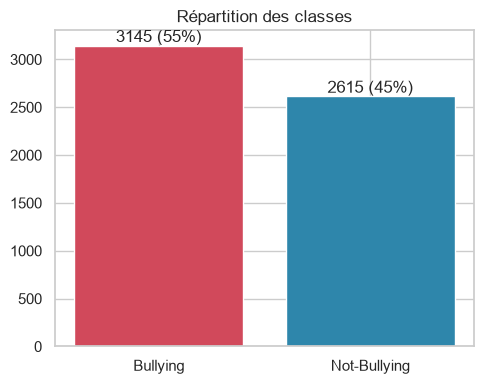

In [13]:
data = pd.DataFrame(list(col.find({}, {"_id": 0, "loaded_at": 0})))
print(len(data), "messages lus depuis MongoDB")

fig, ax = plt.subplots(figsize=(5, 4))
vc = data["label_name"].value_counts()
ax.bar(vc.index, vc.values, color=[PALETTE[k] for k in vc.index])
for i, v in enumerate(vc.values):
    ax.text(i, v, f"{v} ({v/len(data):.0%})", ha="center", va="bottom")
ax.set_title("Répartition des classes")
savefig(fig, "01_classes.png")

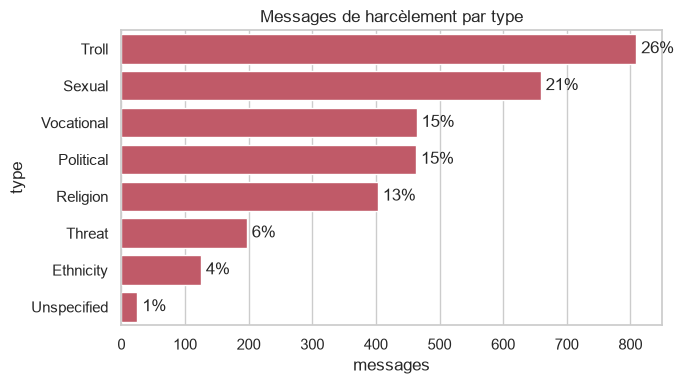

In [14]:
bully = data[data.label == 1]
tv = bully["type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=tv.values, y=tv.index, ax=ax, color="#d1495b")
for i, v in enumerate(tv.values):
    ax.text(v, i, f" {v/tv.sum():.0%}", va="center")
ax.set_title("Messages de harcèlement par type"); ax.set_xlabel("messages")
savefig(fig, "02_types.png")

In [15]:
feats = ["char_len", "word_count", "upper_ratio", "n_exclam", "n_question", "has_profanity"]
data.groupby("label_name")[feats].mean().round(3)

,char_len,word_count,upper_ratio,n_exclam,n_question,has_profanity
label_name,,,,,,
Bullying,55.993,9.455,0.033,0.167,0.047,0.039
Not-Bullying,56.352,9.780,0.033,0.125,0.009,0.008


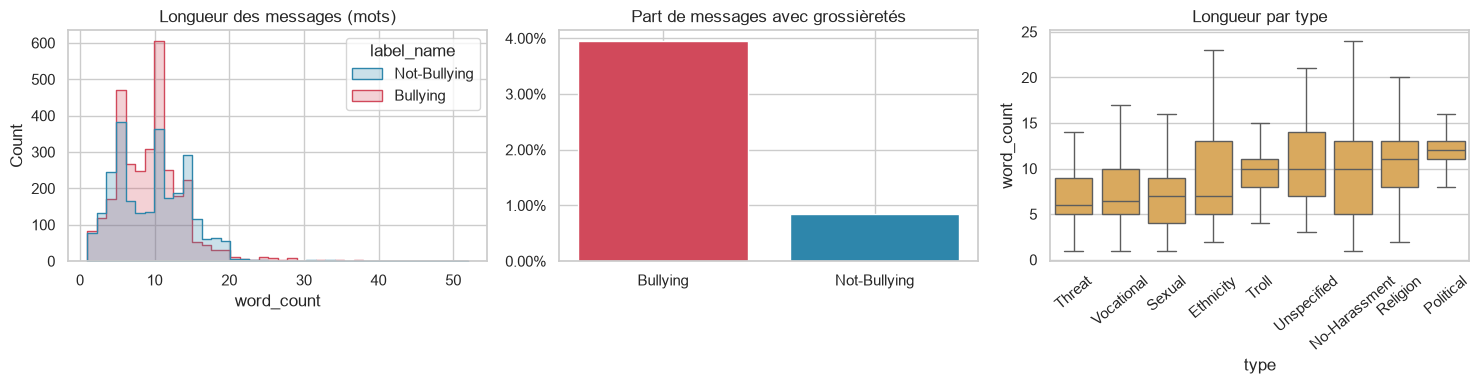

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data, x="word_count", hue="label_name", palette=PALETTE, bins=40, element="step", ax=axes[0])
axes[0].set_title("Longueur des messages (mots)")
prof = data.groupby("label_name")["has_profanity"].mean()
axes[1].bar(prof.index, prof.values, color=[PALETTE[k] for k in prof.index])
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].set_title("Part de messages avec grossièretés")
order = data.groupby("type")["word_count"].median().sort_values().index
sns.boxplot(data, x="type", y="word_count", order=order, ax=axes[2], color="#edae49", showfliers=False)
axes[2].tick_params(axis="x", rotation=40); axes[2].set_title("Longueur par type")
savefig(fig, "03_longueur_grossieretes.png")

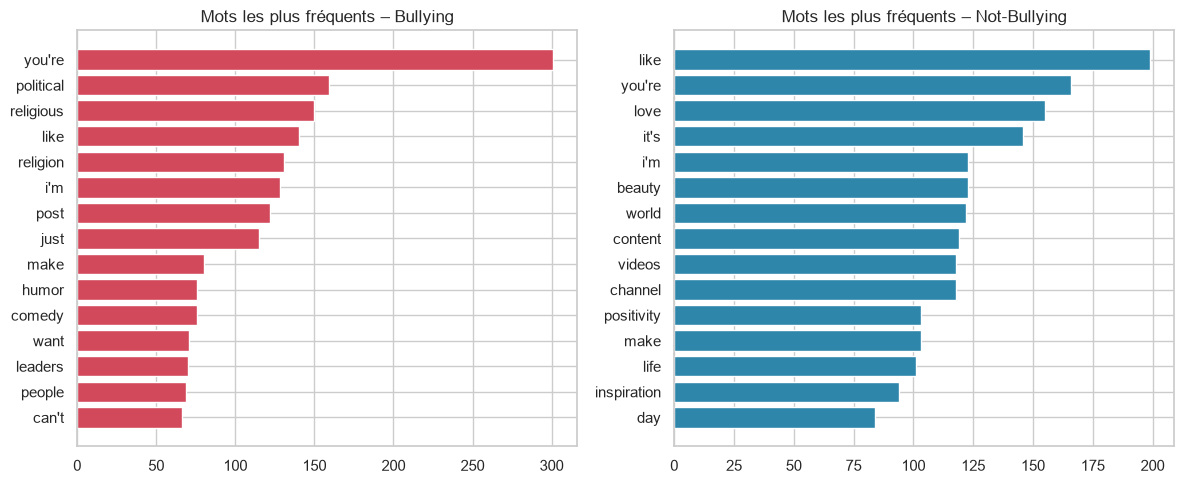

,Ethnicity,Political,Religion,Sexual,Threat,Troll,Vocational
0,people,political,religious,want,you're,post,you're
1,nigga,public,religion,you're,kill,you're,just
2,fuck,undermines,i'm,sexual,just,like,job
3,country,leaders,critical,make,life,comedy,work
4,white,government,fear,sex,i'm,humor,you'll
5,nigger,lack,historical,i'll,killed,instagram,health
6,society,erosion,muslims,fuck,don't,laughter,economy
7,work,trust,leaders,hot,make,just,it's
8,dumb,neglect,skeptical,can't,like,posts,life
9,bad,threatens,concerned,love,loser,reason,going


In [17]:
def top_words(texts, n=15):
    cnt = Counter(w for t in texts for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2)
    return cnt.most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, g) in zip(axes, data.groupby("label_name")):
    words = top_words(g["clean_text"])
    ax.barh([w for w, _ in words][::-1], [c for _, c in words][::-1], color=PALETTE[name])
    ax.set_title(f"Mots les plus fréquents – {name}")
savefig(fig, "04_mots_frequents.png")

pd.DataFrame({t: [w for w, _ in top_words(g["clean_text"], 10)]
              for t, g in bully.groupby("type") if t != "Unspecified"})

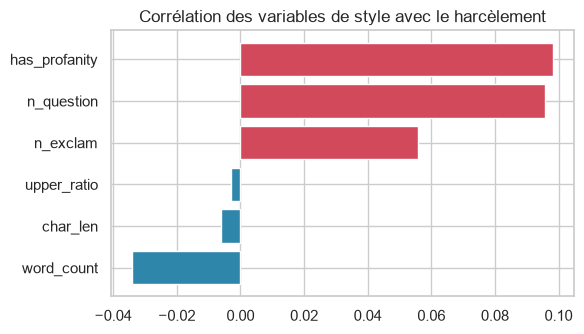

In [18]:
corr = data[feats + ["label"]].corr()["label"].drop("label").sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(corr.index, corr.values, color=["#2e86ab" if v < 0 else "#d1495b" for v in corr.values])
ax.set_title("Corrélation des variables de style avec le harcèlement")
savefig(fig, "05_correlation.png")

**Tendances observées** :
- Classes assez équilibrées (≈ 55 % harcèlement), donc pas besoin de rééchantillonnage.
- Types dominants : **Troll** (≈ 26 %) et **Sexual** (≈ 21 %), puis Vocational, Political et Religion.
- La **longueur** ne distingue pas les classes. Les messages Sexual et Threat sont les plus courts, Political et Religion les plus longs.
- Les grossièretés sont ≈ 5× plus fréquentes dans le harcèlement, mais restent rares : la corrélation de toutes les variables de style est faible (|r| < 0,1).
- ➜ **Le harcèlement est porté par le vocabulaire et le thème** (religion, politique, moquerie/« humor », sexualité, menaces), d'où le choix de modèles basés sur le texte (TF-IDF).

<a id="4"></a>
## 4. Modélisation et prédiction
Deux modèles sur des représentations TF-IDF du texte nettoyé :

| | Modèle A – Régression logistique | Modèle B – Naive Bayes multinomial |
|---|---|---|
| Features | TF-IDF mots (1-2 grammes) **+ caractères** (2-5 grammes, robuste aux fautes) | TF-IDF mots (1-2 grammes) |
| Pourquoi | modèle linéaire discriminant, interprétable (coefficients) | baseline probabiliste classique en texte, très rapide |

Évaluation : split stratifié 80/20 (test jamais vu) + validation croisée 5 folds sur le train.

In [19]:
X, y = data["clean_text"], data["label"].values
X_tr, X_te, y_tr, y_te, type_tr, type_te = train_test_split(
    X, y, data["type"], test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train={len(X_tr)}  test={len(X_te)}")

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", FeatureUnion([
            ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
            ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)),
        ])),
        ("clf", LogisticRegression(C=4.0, max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", MultinomialNB(alpha=0.3)),
    ]),
}

train=4608  test=1152


In [20]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
results, preds, probas = {}, {}, {}

for name, model in models.items():
    cvres = cross_validate(model, X_tr, y_tr, cv=cv, scoring=["f1", "roc_auc"])
    t0 = time.perf_counter(); model.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); p = model.predict_proba(X_te)[:, 1]
    ms = (time.perf_counter() - t0) / len(X_te) * 1000
    yhat = (p >= 0.5).astype(int)
    preds[name], probas[name] = yhat, p
    results[name] = {
        "CV F1 (moy)": cvres["test_f1"].mean(), "CV F1 (écart-type)": cvres["test_f1"].std(),
        "CV ROC-AUC": cvres["test_roc_auc"].mean(),
        "Accuracy": accuracy_score(y_te, yhat), "Precision": precision_score(y_te, yhat),
        "Recall": recall_score(y_te, yhat), "F1": f1_score(y_te, yhat), "ROC-AUC": roc_auc_score(y_te, p),
        "Entraînement (s)": fit_s, "Prédiction (ms/msg)": ms,
    }

for name in models:
    print(f"===== {name} =====")
    print(classification_report(y_te, preds[name], target_names=["Not-Bullying", "Bullying"], digits=3))

===== Logistic Regression =====
              precision    recall  f1-score   support

Not-Bullying      0.909     0.883     0.896       523
    Bullying      0.905     0.927     0.916       629

    accuracy                          0.907      1152
   macro avg      0.907     0.905     0.906      1152
weighted avg      0.907     0.907     0.907      1152

===== Naive Bayes =====
              precision    recall  f1-score   support

Not-Bullying      0.925     0.874     0.899       523
    Bullying      0.900     0.941     0.920       629

    accuracy                          0.911      1152
   macro avg      0.912     0.907     0.909      1152
weighted avg      0.911     0.911     0.910      1152



In [21]:
# Prédiction sur de nouveaux messages
samples = ["you are a worthless idiot, nobody wants you here",
           "I will find you and kill you",
           "Thanks for sharing, this video really inspired me",
           "Politicians like you are a disgrace to this country"]
pd.DataFrame({name: m.predict_proba([clean_text(s) for s in samples])[:, 1].round(3)
              for name, m in models.items()}, index=samples).rename_axis("P(Bullying)")

,Logistic Regression,Naive Bayes
P(Bullying),,
"you are a worthless idiot, nobody wants you here",0.979,0.987
I will find you and kill you,0.976,0.925
"Thanks for sharing, this video really inspired me",0.156,0.059
Politicians like you are a disgrace to this country,0.923,0.933


<a id="5"></a>
## 5. Étude comparative des prédictions

In [22]:
res = pd.DataFrame(results).T
res.style.format("{:.4f}").highlight_max(axis=0, subset=["CV F1 (moy)", "CV ROC-AUC", "Accuracy",
                                                          "Precision", "Recall", "F1", "ROC-AUC"], color="#c8e6c9")

,CV F1 (moy),CV F1 (écart-type),CV ROC-AUC,Accuracy,Precision,Recall,F1,ROC-AUC,Entraînement (s),Prédiction (ms/msg)
Logistic Regression,0.9109,0.0072,0.9618,0.9071,0.9053,0.9269,0.9159,0.9678,1.2145,0.2086
Naive Bayes,0.9144,0.0067,0.9666,0.9106,0.8997,0.9412,0.9200,0.9725,0.1939,0.0302


In [23]:
# Test de McNemar : les deux modèles se trompent-ils de façon significativement différente ?
a, b = preds["Logistic Regression"], preds["Naive Bayes"]
n01 = int(((a == y_te) & (b != y_te)).sum())   # LR juste, NB faux
n10 = int(((a != y_te) & (b == y_te)).sum())   # LR faux, NB juste
stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10)
pval = 1 - chi2.cdf(stat, 1)
print(f"LR juste / NB faux : {n01}   |   LR faux / NB juste : {n10}")
print(f"chi2 = {stat:.2f}, p-value = {pval:.3f} ->",
      "différence significative" if pval < 0.05 else "différence NON significative (p >= 0.05)")

LR juste / NB faux : 31   |   LR faux / NB juste : 35
chi2 = 0.14, p-value = 0.712 -> différence NON significative (p >= 0.05)


In [24]:
# Taux de détection (recall) par type de harcèlement
m = pd.DataFrame({"type": type_te.values, "y": y_te, **preds})
per_type = m[m.y == 1].groupby("type")[list(models)].mean().round(3)
per_type["support"] = m[m.y == 1]["type"].value_counts()
per_type.sort_values("Naive Bayes")

,Logistic Regression,Naive Bayes,support
type,,,
Troll,0.863,0.863,161
Sexual,0.908,0.937,142
Threat,0.944,0.944,36
Vocational,0.917,0.952,84
Religion,1.000,1.000,83
Political,0.989,1.000,95
Ethnicity,0.960,1.000,25
Unspecified,1.000,1.000,3


**Lecture** :
- Les deux modèles sont **très proches** (F1 ≈ 0,92, ROC-AUC ≈ 0,97) et stables en validation croisée (écart-type < 0,01).
- **Naive Bayes** a un **meilleur rappel** : il rate moins de harcèlements. La **régression logistique** a une précision légèrement supérieure : elle fait un peu moins de fausses alertes.
- McNemar : p ≫ 0,05, donc **la différence n'est pas statistiquement significative**.
- Les deux modèles détectent presque 100 % des harcèlements Religion / Political / Ethnicity (vocabulaire marqué). La catégorie **Troll** (ironie, moquerie implicite) est la plus difficile (≈ 86 %).
- Naive Bayes est **≈ 5× plus rapide à entraîner** et **≈ 7× plus rapide en prédiction**.

<a id="6"></a>
## 6. Visualisation des résultats

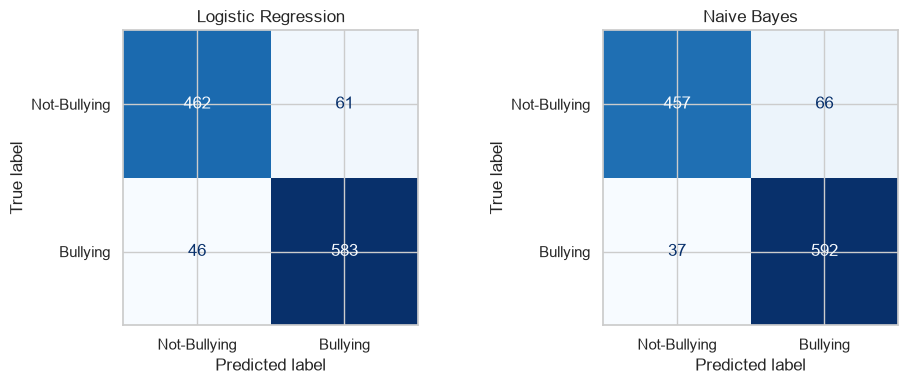

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_te, preds[name], display_labels=["Not-Bullying", "Bullying"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
savefig(fig, "06_matrices_confusion.png")

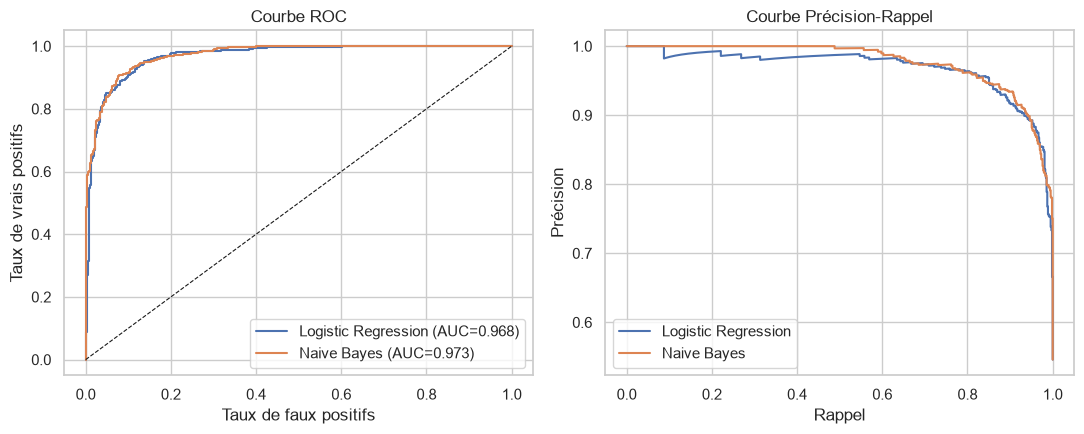

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_te, probas[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={results[name]['ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_te, probas[name])
    axes[1].plot(rc, pr, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(title="Courbe ROC", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs")
axes[1].set(title="Courbe Précision-Rappel", xlabel="Rappel", ylabel="Précision")
for ax in axes: ax.legend()
savefig(fig, "07_roc_pr.png")

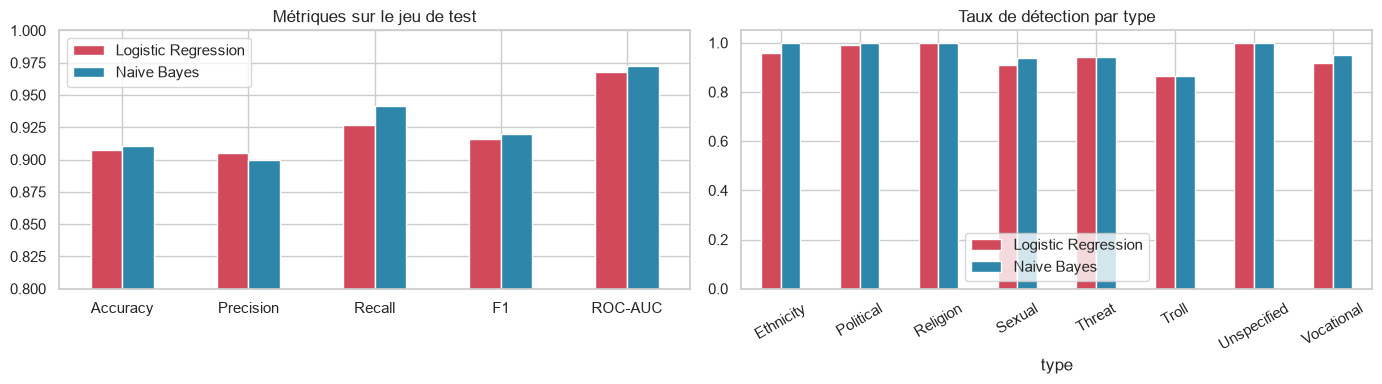

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
res[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].T.plot.bar(ax=axes[0], color=["#d1495b", "#2e86ab"])
axes[0].set_ylim(0.8, 1); axes[0].set_title("Métriques sur le jeu de test"); axes[0].tick_params(axis="x", rotation=0)
per_type[list(models)].plot.bar(ax=axes[1], color=["#d1495b", "#2e86ab"])
axes[1].set_ylim(0, 1.05); axes[1].set_title("Taux de détection par type"); axes[1].tick_params(axis="x", rotation=30)
savefig(fig, "08_metriques.png")

### Facteurs qui influencent la prédiction (coefficients de la régression logistique)

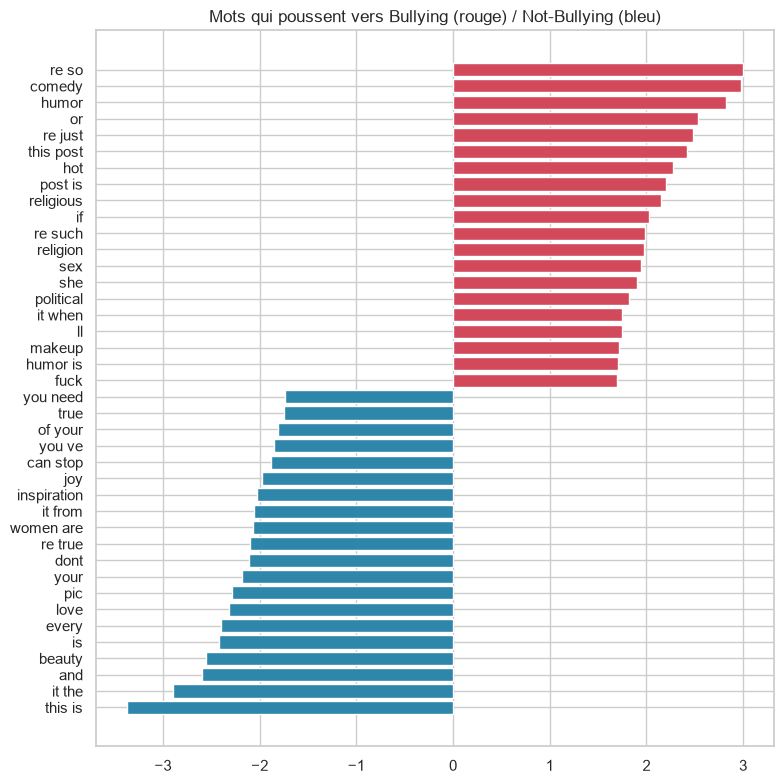

In [28]:
lr = models["Logistic Regression"]
word_vec = lr.named_steps["tfidf"].transformer_list[0][1]
vocab = word_vec.get_feature_names_out()
coefs = lr.named_steps["clf"].coef_[0][:len(vocab)]
order = np.argsort(coefs)
idx = np.concatenate([order[:20], order[-20:]])
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(vocab[idx], coefs[idx], color=["#2e86ab"] * 20 + ["#d1495b"] * 20)
ax.set_title("Mots qui poussent vers Bullying (rouge) / Not-Bullying (bleu)")
savefig(fig, "09_facteurs.png")

In [29]:
# Analyse d'erreurs du modèle retenu
best = "Naive Bayes"
err = pd.DataFrame({"text": X_te.values, "réel": y_te, "P(Bullying)": probas[best].round(3)})
display(Markdown("**Harcèlements manqués (faux négatifs)**"))
display(err[(err["réel"] == 1) & (err["P(Bullying)"] < 0.5)].nsmallest(5, "P(Bullying)"))
display(Markdown("**Fausses alertes (faux positifs)**"))
display(err[(err["réel"] == 0) & (err["P(Bullying)"] >= 0.5)].nlargest(5, "P(Bullying)"))

**Harcèlements manqués (faux négatifs)**

,text,réel,P(Bullying)
462,you've got the talent to make anyone laugh!,1,0.100
420,you've got the midas touch but for humor!,1,0.131
285,j patre khay se patroi futo kore soytan,1,0.132
725,what you re doing feels amazing,1,0.144
571,i hope your day is as bright as your wit!,1,0.157


**Fausses alertes (faux positifs)**

,text,réel,P(Bullying)
782,government is incompetent,0,0.934
1060,if you ever need a hand just let me know,0,0.914
66,hot women,0,0.902
316,she enjoys flowers,0,0.898
140,never be reluctant to get in touch if you need anything,0,0.895


<a id="7"></a>
## 7. Conteneurisation avec FastAPI et Docker
### 7.1 Sauvegarde du modèle retenu
**Naive Bayes** est retenu : performances équivalentes (différence non significative), **meilleur rappel** (en modération, un harcèlement manqué coûte plus cher qu'une fausse alerte), et beaucoup plus rapide. Il est **ré-entraîné sur toutes les données** avant d'être exporté.

In [30]:
final_model = models[best].fit(X, y)
joblib.dump(final_model, MODELS_DIR / "best_model.joblib")
(MODELS_DIR / "metadata.json").write_text(json.dumps({
    "best_model": best, "threshold": 0.5, "trained_on": len(X),
    "test_metrics": {k: round(v, 4) for k, v in results[best].items()},
}, indent=2))

# Versions exactes des librairies -> l'API charge le modèle avec les mêmes versions
from importlib.metadata import version
pkgs = ["scikit-learn", "numpy", "scipy", "joblib", "pandas", "fastapi", "uvicorn", "pymongo", "pydantic"]
(API_DIR / "requirements.txt").write_text("\n".join(f"{p}=={version(p)}" for p in pkgs) + "\n")
print((API_DIR / "requirements.txt").read_text())

scikit-learn==1.9.1
numpy==2.5.4
scipy==1.18.1
joblib==1.6.0
pandas==3.1.1
fastapi==0.162.0
uvicorn==0.54.0
pymongo==4.19.0
pydantic==2.14.3



### 7.2 Application FastAPI
Endpoints : `GET /health`, `GET /model`, `POST /predict`, `POST /predict/batch`, `GET /stats` (statistiques calculées en direct dans MongoDB).
Au démarrage, si la collection MongoDB est vide (nouveau déploiement), l'API la remplit avec les données nettoyées.

In [31]:
%%writefile api/app.py
"""Cyberbullying detection API: serves the model selected in the notebook + MongoDB statistics."""
import json
import os
from contextlib import asynccontextmanager
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from fastapi import FastAPI, HTTPException
from fastapi.responses import FileResponse
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel, Field
from pymongo import MongoClient

from text_utils import clean_text

BASE = Path(os.getenv("APP_HOME", Path(__file__).resolve().parent.parent))
MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
DB, COLLECTION = "cyberbullying", "messages"
state: dict = {}


def seed_mongo():
    """Load the cleaned dataset into MongoDB if the collection is empty (fresh deployment)."""
    try:
        col = state["mongo"][DB][COLLECTION]
        if col.estimated_document_count() == 0:
            col.insert_many(pd.read_csv(BASE / "data" / "clean_cyberbullying.csv").to_dict("records"))
    except Exception as e:
        print(f"MongoDB seeding skipped: {e}")


@asynccontextmanager
async def lifespan(_: FastAPI):
    state["model"] = joblib.load(BASE / "models" / "best_model.joblib")
    vec, clf = state["model"].named_steps["tfidf"], state["model"].named_steps["clf"]
    state["vocab"] = vec.get_feature_names_out()
    # Naive Bayes: how much each word/bigram pushes towards "Bullying" (log-odds)
    state["word_weight"] = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
    state["meta"] = json.loads((BASE / "models" / "metadata.json").read_text())
    state["mongo"] = MongoClient(MONGO_URI, serverSelectionTimeoutMS=3000)
    seed_mongo()
    yield
    state["mongo"].close()


app = FastAPI(title="Cyberbullying Detection API", version="1.0.0", lifespan=lifespan)

# ---- Web dashboard (HTML/CSS/JS served by FastAPI) ----
STATIC = Path(__file__).resolve().parent / "static"
app.mount("/static", StaticFiles(directory=STATIC), name="static")



class Message(BaseModel):
    text: str = Field(..., min_length=1, max_length=5000, examples=["you are so stupid nobody likes you"])


class Batch(BaseModel):
    texts: list[str] = Field(..., min_length=1, max_length=1000)


class Prediction(BaseModel):
    text: str
    label: str
    is_bullying: bool
    probability_bullying: float
    key_words: list[str] = []


def key_words(clean_texts: list[str], top: int = 3) -> list[list[str]]:
    """Words of each message that pushed the model most towards 'Bullying'."""
    X = state["model"].named_steps["tfidf"].transform(clean_texts)
    out = []
    for i in range(X.shape[0]):
        row = X.getrow(i)
        scores = row.data * state["word_weight"][row.indices]
        best = [row.indices[j] for j in np.argsort(scores)[::-1][:top] if scores[j] > 0]
        out.append([str(state["vocab"][k]) for k in best])
    return out


def predict_texts(texts: list[str]) -> list[Prediction]:
    cleaned = [clean_text(t) for t in texts]
    probs = state["model"].predict_proba(cleaned)[:, 1]
    thr = state["meta"]["threshold"]
    preds = [Prediction(text=t, label="Bullying" if p >= thr else "Not-Bullying",
                        is_bullying=bool(p >= thr), probability_bullying=round(float(p), 4),
                        key_words=kw if p >= thr else [])
             for t, p, kw in zip(texts, probs, key_words(cleaned))]
    try:  # log predictions for monitoring; never fail the request because of it
        state["mongo"][DB]["predictions"].insert_many(
            [{**p.model_dump(), "at": datetime.now(timezone.utc)} for p in preds])
    except Exception:
        pass
    return preds


@app.get("/", include_in_schema=False)
def home():
    """Simple web page for non-technical users."""
    return FileResponse(STATIC / "index.html")


@app.get("/health")
def health():
    try:
        state["mongo"].admin.command("ping")
        mongo = "up"
    except Exception:
        mongo = "down"
    return {"status": "ok", "model": state["meta"]["best_model"], "mongo": mongo}


@app.get("/model")
def model_info():
    return state["meta"]


@app.post("/predict", response_model=Prediction)
def predict(msg: Message):
    return predict_texts([msg.text])[0]


@app.post("/predict/batch", response_model=list[Prediction])
def predict_batch(batch: Batch):
    return predict_texts(batch.texts)


@app.get("/stats")
def stats():
    try:
        col = state["mongo"][DB][COLLECTION]
        if col.estimated_document_count() == 0:  # DB was unreachable at startup -> seed now
            seed_mongo()
        by_label = {r["_id"]: r["n"] for r in col.aggregate([{"$group": {"_id": "$label_name", "n": {"$sum": 1}}}])}
        by_type = list(col.aggregate([
            {"$match": {"label": 1}},
            {"$group": {"_id": "$type", "n": {"$sum": 1}, "avg_words": {"$avg": "$word_count"}}},
            {"$sort": {"n": -1}}]))
    except Exception as e:
        raise HTTPException(503, f"MongoDB unavailable: {e}")
    return {"total": sum(by_label.values()), "by_label": by_label,
            "bullying_by_type": [{"type": r["_id"], "count": r["n"], "avg_words": round(r["avg_words"], 1)}
                                 for r in by_type]}

Overwriting api/app.py


### 7.3 Interface web pour les utilisateurs non techniques
La page `/docs` (Swagger) est destinée aux développeurs. Pour un utilisateur métier (modérateur, client), l'API sert aussi un **tableau de bord web à son adresse principale** (`http://localhost:8000/`).

Le tableau de bord est construit avec **Bootstrap 5.3**, Bootstrap Icons et **Chart.js**. Il s'adapte au mobile et au mode sombre, et ne nécessite aucune étape de build. Il est servi directement par FastAPI.
- **Message** : score de risque (jauge 0-100), verdict, niveau de risque, termes déterminants et recommandation d'action.
- **Lot de messages** : un message par ligne, synthèse (analysés / signalés / conformes), tableau trié par score et **export CSV**.
- **Historique** des analyses de la session.
- **Données d'apprentissage** : indicateurs clés (volume, F1, rappel) et graphiques par catégorie, lus dans MongoDB via `/stats` et `/model`.
- Liens partageables : `/?q=<message>` pré-remplit et lance l'analyse.


**Design** : grille Bootstrap, typographie Inter, palette indigo neutre, cartes à bordures fines, états vides, chargement et erreur, mode sombre automatique, responsive mobile, accessibilité (navigation clavier, lecteurs d'écran, contrastes AA).

In [32]:
%%writefile api/static/index.html
<!doctype html>
<html lang="fr">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<meta name="description" content="Sentinelle : détection automatique des messages de harcèlement sur les réseaux sociaux.">
<title>Sentinelle · Détection du harcèlement</title>
<script src="/static/theme.js"></script>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="stylesheet" href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap">
<link rel="stylesheet" href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/css/bootstrap.min.css">
<link rel="stylesheet" href="https://cdn.jsdelivr.net/npm/bootstrap-icons@1.11.3/font/bootstrap-icons.min.css">
<link rel="stylesheet" href="/static/app.css">
</head>
<body>
<a class="visually-hidden-focusable skip-link" href="#main">Aller au contenu principal</a>

<header>
<nav class="navbar sticky-top" aria-label="Navigation principale">
  <div class="container-xl">
    <a class="navbar-brand d-flex align-items-center gap-2 fw-semibold" href="/">
      <span class="brand-mark" aria-hidden="true"><i class="bi bi-shield-check"></i></span> Sentinelle
      <span class="badge rounded-pill bg-body-tertiary text-body-secondary border fw-medium d-none d-sm-inline">Modération</span>
    </a>
    <div class="d-flex align-items-center gap-3">
      <span class="small text-body-secondary d-none d-md-inline" id="apiStatus" role="status">
        <span class="status-dot bg-secondary me-1" aria-hidden="true"></span>Connexion...
      </span>
      <a class="btn btn-sm btn-outline-secondary" href="/docs" target="_blank" rel="noopener">
        <i class="bi bi-code-slash me-1" aria-hidden="true"></i><span class="d-none d-sm-inline">Documentation API</span>
        <span class="visually-hidden d-sm-none">Documentation API</span>
        <span class="visually-hidden">(nouvel onglet)</span>
      </a>
    </div>
  </div>
</nav>
</header>

<main class="container-xl py-4" id="main" tabindex="-1">
  <div class="mb-4">
    <p class="eyebrow mb-1">Tableau de bord</p>
    <h1 class="h3 fw-bold mb-1">Analyse des messages</h1>
    <p class="text-body-secondary mb-0">Détectez automatiquement les messages de harcèlement publiés sur vos réseaux sociaux.</p>
  </div>

  <!-- Screen-reader announcements of results -->
  <div class="visually-hidden" aria-live="polite" aria-atomic="true" id="announce"></div>

  <div class="row g-4">
    <!-- Input -->
    <div class="col-lg-7">
      <section class="card h-100" aria-labelledby="inputTitle">
        <div class="card-header d-flex justify-content-between align-items-center flex-wrap gap-2">
          <h2 class="card-title" id="inputTitle">Nouveau contrôle</h2>
          <div class="nav nav-pills gap-1" role="tablist" aria-label="Type d'analyse">
            <button class="nav-link active py-1 px-3" role="tab" id="tab-one" data-mode="one"
                    aria-selected="true" aria-controls="inputPanel" tabindex="0">
              <i class="bi bi-chat-left-text me-1" aria-hidden="true"></i>Message</button>
            <button class="nav-link py-1 px-3" role="tab" id="tab-many" data-mode="many"
                    aria-selected="false" aria-controls="inputPanel" tabindex="-1">
              <i class="bi bi-list-ul me-1" aria-hidden="true"></i>Lot de messages</button>
          </div>
        </div>
        <div class="card-body" role="tabpanel" id="inputPanel" aria-labelledby="tab-one">
          <label for="input" class="form-label fw-medium" id="inputLabel">Contenu du message</label>
          <textarea id="input" class="form-control" maxlength="20000" lang="en"
                    aria-describedby="inputHelp counter"
                    placeholder="Collez le message à vérifier..."></textarea>
          <div class="d-flex justify-content-between mt-2 small text-body-secondary">
            <span id="inputHelp"><i class="bi bi-info-circle me-1" aria-hidden="true"></i><span id="inputHelpText">Le modèle est entraîné sur des messages en anglais.</span></span>
            <span id="counter">0 caractère</span>
          </div>
          <div class="alert alert-danger py-2 mt-3 mb-0 d-none" id="err" role="alert"></div>
          <div class="d-flex flex-wrap gap-2 mt-3">
            <button class="btn btn-brand px-4" id="go" type="button">
              <span class="spinner-border spinner-border-sm me-2 d-none" id="spin" aria-hidden="true"></span>
              <span id="goLabel">Analyser</span>
            </button>
            <div class="dropdown">
              <button class="btn btn-outline-secondary dropdown-toggle" type="button" data-bs-toggle="dropdown" aria-expanded="false">
                <i class="bi bi-lightning me-1" aria-hidden="true"></i>Exemples
              </button>
              <ul class="dropdown-menu" id="examples"></ul>
            </div>
            <button class="btn btn-link text-body-secondary text-decoration-none ms-auto" id="clear" type="button">
              <i class="bi bi-x-lg me-1" aria-hidden="true"></i>Effacer
            </button>
          </div>
          <p class="small text-body-secondary mt-3 mb-0">Astuce : <kbd>Ctrl</kbd> / <kbd>⌘</kbd> + <kbd>Entrée</kbd> pour lancer l'analyse.</p>
        </div>
      </section>
    </div>

    <!-- Result -->
    <div class="col-lg-5">
      <section class="card h-100" aria-labelledby="resultTitle">
        <div class="card-header"><h2 class="card-title" id="resultTitle">Résultat</h2></div>
        <div class="card-body">
          <div class="empty-state" id="empty">
            <i class="bi bi-search d-block mb-2" aria-hidden="true"></i>
            <p class="fw-medium text-body mb-0">Aucune analyse pour le moment</p>
            <p class="small mb-0">Saisissez un message puis cliquez sur « Analyser ».</p>
          </div>

          <div class="d-none" id="result">
            <div class="d-flex align-items-center gap-4">
              <div class="gauge" id="gauge" role="img" aria-label="Score de risque">
                <div aria-hidden="true"><span><b id="score">0</b><br><small>score de risque</small></span></div>
              </div>
              <div>
                <span class="badge rounded-pill mb-2" id="badge"></span>
                <p class="h5 fw-bold mb-1" id="verdict"></p>
                <p class="small fw-medium mb-0" id="level"></p>
              </div>
            </div>
            <hr>
            <h3 class="eyebrow mb-2">Termes déterminants</h3>
            <ul id="keywords" class="list-unstyled d-flex flex-wrap gap-2 mb-0" lang="en"></ul>
            <p class="small text-body-secondary mt-3 mb-0" id="recommendation"></p>
          </div>

          <div class="d-none" id="batchSummary">
            <dl class="row g-3 text-center mb-0">
              <div class="col-4 d-flex flex-column-reverse"><dt class="small text-body-secondary fw-normal">analysés</dt><dd class="kpi-value mb-0" id="bTotal">0</dd></div>
              <div class="col-4 d-flex flex-column-reverse"><dt class="small text-body-secondary fw-normal">signalés</dt><dd class="kpi-value text-danger-emphasis mb-0" id="bBad">0</dd></div>
              <div class="col-4 d-flex flex-column-reverse"><dt class="small text-body-secondary fw-normal">conformes</dt><dd class="kpi-value text-success-emphasis mb-0" id="bOk">0</dd></div>
            </dl>
            <div class="progress progress-thin mt-3" aria-hidden="true"><div class="progress-bar bg-danger" id="bBar"></div></div>
            <p class="small text-body-secondary mt-2 mb-0">Le détail de chaque message est affiché dans le tableau ci-dessous.</p>
          </div>
        </div>
      </section>
    </div>

    <!-- Batch table -->
    <div class="col-12 d-none" id="tableCard">
      <section class="card" aria-labelledby="tableTitle">
        <div class="card-header d-flex justify-content-between align-items-center">
          <h2 class="card-title" id="tableTitle">Détail du lot</h2>
          <button class="btn btn-sm btn-outline-secondary" id="export" type="button">
            <i class="bi bi-download me-1" aria-hidden="true"></i>Exporter CSV</button>
        </div>
        <div class="table-responsive">
          <table class="table table-hover align-middle mb-0">
            <caption class="visually-hidden">Résultat de chaque message du lot, trié du score le plus élevé au plus faible</caption>
            <thead><tr>
              <th scope="col" class="col-status">Statut</th><th scope="col">Message</th>
              <th scope="col" class="col-score">Score</th><th scope="col">Termes déterminants</th>
            </tr></thead>
            <tbody id="rows"></tbody>
          </table>
        </div>
      </section>
    </div>

    <!-- History -->
    <div class="col-12">
      <section class="card history" aria-labelledby="histTitle">
        <div class="card-header d-flex justify-content-between align-items-center">
          <h2 class="card-title" id="histTitle">Historique de la session</h2>
          <span class="small text-body-secondary" id="histCount">0 analyse</span>
        </div>
        <ul class="list-group list-group-flush" id="history">
          <li class="list-group-item text-body-secondary small py-3">Les analyses effectuées apparaîtront ici.</li>
        </ul>
      </section>
    </div>
  </div>

  <!-- Dataset overview -->
  <section aria-labelledby="dataTitle">
    <div class="mt-5 mb-3">
      <p class="eyebrow mb-1">Modèle</p>
      <h2 class="h5 fw-bold mb-0" id="dataTitle">Données d'apprentissage</h2>
    </div>
    <div class="row g-4">
      <div class="col-sm-6 col-xl-3"><div class="card p-3 h-100"><div class="d-flex gap-3 align-items-center">
        <div class="kpi-icon bg-primary-subtle text-primary-emphasis" aria-hidden="true"><i class="bi bi-chat-square-text"></i></div>
        <div><p class="kpi-value mb-0" id="kTotal">–</p><p class="small text-body-secondary mb-0">messages étudiés</p></div></div></div></div>
      <div class="col-sm-6 col-xl-3"><div class="card p-3 h-100"><div class="d-flex gap-3 align-items-center">
        <div class="kpi-icon bg-danger-subtle text-danger-emphasis" aria-hidden="true"><i class="bi bi-exclamation-octagon"></i></div>
        <div><p class="kpi-value mb-0" id="kBully">–</p><p class="small text-body-secondary mb-0">cas de harcèlement</p></div></div></div></div>
      <div class="col-sm-6 col-xl-3"><div class="card p-3 h-100"><div class="d-flex gap-3 align-items-center">
        <div class="kpi-icon bg-success-subtle text-success-emphasis" aria-hidden="true"><i class="bi bi-bullseye"></i></div>
        <div><p class="kpi-value mb-0" id="kF1">–</p><p class="small text-body-secondary mb-0">score F1 (test)</p></div></div></div></div>
      <div class="col-sm-6 col-xl-3"><div class="card p-3 h-100"><div class="d-flex gap-3 align-items-center">
        <div class="kpi-icon bg-warning-subtle text-warning-emphasis" aria-hidden="true"><i class="bi bi-search-heart"></i></div>
        <div><p class="kpi-value mb-0" id="kRecall">–</p><p class="small text-body-secondary mb-0">des harcèlements détectés</p></div></div></div></div>

      <div class="col-lg-8"><div class="card h-100">
        <div class="card-header"><h3 class="card-title" id="typesTitle">Harcèlement par catégorie</h3></div>
        <div class="card-body chart-box">
          <canvas id="typesChart" role="img" aria-labelledby="typesTitle" aria-describedby="typesDesc"></canvas>
          <p class="visually-hidden" id="typesDesc">Chargement des données...</p>
        </div>
      </div></div>
      <div class="col-lg-4"><div class="card h-100">
        <div class="card-header"><h3 class="card-title" id="labelTitle">Répartition des messages</h3></div>
        <div class="card-body chart-box d-flex align-items-center justify-content-center">
          <canvas id="labelChart" role="img" aria-labelledby="labelTitle" aria-describedby="labelDesc"></canvas>
          <p class="visually-hidden" id="labelDesc">Chargement des données...</p>
        </div>
      </div></div>
    </div>
  </section>
</main>

<footer class="container-xl d-flex flex-wrap justify-content-between gap-2 border-top mt-5 pt-3 pb-4">
  <span>Résultats fournis à titre d'aide à la décision. Une vérification humaine reste recommandée.</span>
  <span id="modelName">Modèle : –</span>
</footer>

<script src="https://cdn.jsdelivr.net/npm/bootstrap@5.3.3/dist/js/bootstrap.bundle.min.js"></script>
<script src="https://cdn.jsdelivr.net/npm/chart.js@4.4.1/dist/chart.umd.min.js"></script>
<script src="/static/app.js"></script>
</body>
</html>

Overwriting api/static/index.html


In [33]:
%%writefile api/static/theme.js
// Loaded in <head> before the CSS so the page never flashes the wrong theme.
(function () {
  const mq = window.matchMedia("(prefers-color-scheme: dark)");
  const apply = () => document.documentElement.setAttribute("data-bs-theme", mq.matches ? "dark" : "light");
  apply();
  mq.addEventListener("change", apply);
})();

Overwriting api/static/theme.js


In [34]:
%%writefile api/static/app.css
:root, [data-bs-theme="light"] {
  --bs-body-font-family: "Inter", system-ui, -apple-system, "Segoe UI", sans-serif;
  --bs-body-bg: #f5f6fa;
  --brand: #4f46e5;          /* text/accents: 6.3:1 on white */
  --brand-btn: #4f46e5;      /* white text on it: 6.3:1 */
  --brand-btn-hover: #4338ca;
  --brand-soft: #eef2ff;
  --card-border: #e6e8ef;
}
[data-bs-theme="dark"] {
  --bs-body-font-family: "Inter", system-ui, -apple-system, "Segoe UI", sans-serif;
  --bs-body-bg: #0f1218;
  --brand: #a5b4fc;          /* accents on dark: 9.6:1 */
  --brand-btn: #4f46e5;      /* keep white button text >= 4.5:1 (WCAG AA) */
  --brand-btn-hover: #6366f1;
  --brand-soft: #1e1b4b;
  --card-border: #232836;
}

body { font-size: .935rem; display: flex; flex-direction: column; min-height: 100vh; }
main { flex: 1 0 auto; }
main:focus { outline: none; }
.skip-link { position: absolute; top: .5rem; left: .5rem; z-index: 1080; padding: .5rem 1rem;
             background: var(--brand-btn); color: #fff; border-radius: 8px; }

.navbar { background: var(--bs-body-bg); border-bottom: 1px solid var(--card-border); }
.brand-mark { width: 32px; height: 32px; border-radius: 8px; background: var(--brand-btn); color: #fff;
              display: inline-flex; align-items: center; justify-content: center; }

.card { border: 1px solid var(--card-border); border-radius: 12px; box-shadow: 0 1px 2px rgba(16, 24, 40, .04); overflow: hidden; }
.card-header { background: transparent; border-bottom: 1px solid var(--card-border); padding: 1rem 1.25rem; }
.card-title { font-weight: 600; font-size: 1rem; margin: 0; }
.eyebrow { font-size: .75rem; font-weight: 600; letter-spacing: .06em; text-transform: uppercase; color: var(--bs-secondary-color); }

.btn-brand { --bs-btn-bg: var(--brand-btn); --bs-btn-border-color: var(--brand-btn); --bs-btn-color: #fff;
             --bs-btn-hover-bg: var(--brand-btn-hover); --bs-btn-hover-border-color: var(--brand-btn-hover); --bs-btn-hover-color: #fff;
             --bs-btn-active-bg: var(--brand-btn-hover); --bs-btn-active-border-color: var(--brand-btn-hover); --bs-btn-active-color: #fff;
             --bs-btn-disabled-bg: var(--brand-btn); --bs-btn-disabled-border-color: var(--brand-btn); --bs-btn-disabled-color: #fff;
             --bs-btn-focus-shadow-rgb: 99, 102, 241; font-weight: 600; }
.nav-pills .nav-link { color: var(--bs-secondary-color); font-weight: 500; }
.nav-pills .nav-link.active { background: var(--brand-soft); color: var(--brand); }
textarea.form-control { resize: vertical; min-height: 150px; }
.form-control:focus { border-color: var(--brand); box-shadow: 0 0 0 .2rem rgba(99, 102, 241, .25); }
/* Visible keyboard focus everywhere (WCAG 2.4.7) */
:focus-visible { outline: 2px solid var(--brand); outline-offset: 2px; }

.empty-state { color: var(--bs-secondary-color); text-align: center; padding: 2.5rem 1rem; }
.empty-state .bi { font-size: 2.25rem; opacity: .5; }

.gauge { --v: 0; --c: #16a34a; width: 132px; height: 132px; border-radius: 50%; flex: none;
         background: conic-gradient(var(--c) calc(var(--v) * 1%), var(--bs-tertiary-bg) 0);
         display: grid; place-items: center; }
.gauge > div { width: 104px; height: 104px; border-radius: 50%; background: var(--bs-body-bg);
               display: grid; place-items: center; text-align: center; }
.card .gauge > div { background: var(--bs-card-bg, var(--bs-body-bg)); }
.gauge b { font-size: 1.6rem; line-height: 1; }
.gauge small { color: var(--bs-secondary-color); font-size: .72rem; }
.kw { font-weight: 500; }

.kpi-icon { width: 40px; height: 40px; border-radius: 10px; display: grid; place-items: center; font-size: 1.15rem; }
.kpi-value { font-size: 1.6rem; font-weight: 700; line-height: 1.1; }
.progress-thin { height: 8px; }

.history .list-group-item { border-color: var(--card-border); }
.history .txt { overflow: hidden; text-overflow: ellipsis; white-space: nowrap; min-width: 0; }
.table thead th { background: var(--bs-tertiary-bg); color: var(--bs-secondary-color); font-size: .75rem;
                  font-weight: 600; text-transform: uppercase; letter-spacing: .04em; border-bottom-width: 1px; }
.table td.msg { max-width: 420px; overflow-wrap: anywhere; }
.col-status { width: 130px; } .col-score { width: 160px; }
.score-bar { height: 6px; width: 90px; }
.status-dot { width: 8px; height: 8px; border-radius: 50%; display: inline-block; }
.chart-box { position: relative; min-height: 280px; }
footer { color: var(--bs-secondary-color); font-size: .82rem; }

@media (prefers-reduced-motion: reduce) {
  *, *::before, *::after { transition: none !important; animation: none !important; }
}

Overwriting api/static/app.css


In [35]:
%%writefile api/static/app.js
"use strict";
// Sentinelle front-end (Bootstrap 5 + Chart.js).

const $ = (id) => document.getElementById(id);
function el(tag, className, text) {
  const e = document.createElement(tag);
  if (className) e.className = className;
  if (text !== undefined) e.textContent = text;
  return e;
}
function icon(name, extra = "") {
  const i = el("i", `bi ${name} ${extra}`.trim());
  i.setAttribute("aria-hidden", "true");
  return i;
}

const TYPES = { Troll: "Moquerie / trolling", Sexual: "Harcèlement sexuel", Vocational: "Travail / études",
  Political: "Politique", Religion: "Religion", Threat: "Menaces", Ethnicity: "Origine / racisme" };
const EXAMPLES = [
  "you are a worthless idiot, nobody wants you here",
  "I will find you and kill you",
  "Politicians like you are a disgrace to this country",
  "Thanks for sharing, this video really inspired me",
  "Have a wonderful day everyone!",
];
let mode = "one", lastBatch = [], history = [];
const pct = (p) => Math.round(p * 100);

function level(p) {
  if (p >= 0.8) return { txt: "Risque élevé", cls: "text-danger-emphasis", color: "#dc2626",
    reco: "Recommandation : masquer le message et le transmettre à un modérateur." };
  if (p >= 0.5) return { txt: "Risque modéré", cls: "text-warning-emphasis", color: "#ea580c",
    reco: "Recommandation : faire vérifier le message par un modérateur." };
  if (p >= 0.2) return { txt: "Risque faible", cls: "text-success-emphasis", color: "#ca8a04", reco: "Aucune action nécessaire." };
  return { txt: "Risque très faible", cls: "text-success-emphasis", color: "#16a34a", reco: "Aucune action nécessaire." };
}
function announce(msg) {           // read by screen readers via aria-live
  $("announce").textContent = "";
  setTimeout(() => { $("announce").textContent = msg; }, 50);
}

// ---------- Tabs (WAI-ARIA tabs pattern: click + arrow keys) ----------
const tabs = Array.from(document.querySelectorAll('[role="tab"]'));
function selectTab(tab, focus) {
  tabs.forEach((t) => {
    const on = t === tab;
    t.classList.toggle("active", on);
    t.setAttribute("aria-selected", String(on));
    t.tabIndex = on ? 0 : -1;
  });
  if (focus) tab.focus();
  $("inputPanel").setAttribute("aria-labelledby", tab.id);
  mode = tab.dataset.mode;
  $("inputLabel").textContent = mode === "one" ? "Contenu du message" : "Messages (un par ligne)";
  $("input").placeholder = mode === "one" ? "Collez le message à vérifier..." : "Un message par ligne, jusqu'à 1 000 messages...";
  $("inputHelpText").textContent = mode === "one"
    ? "Le modèle est entraîné sur des messages en anglais." : "Chaque ligne est analysée séparément.";
  updateCounter();
  resetResult();
}
tabs.forEach((t, i) => {
  t.addEventListener("click", () => selectTab(t, false));
  t.addEventListener("keydown", (e) => {
    if (e.key === "ArrowRight" || e.key === "ArrowLeft") {
      e.preventDefault();
      selectTab(tabs[(i + (e.key === "ArrowRight" ? 1 : tabs.length - 1)) % tabs.length], true);
    }
  });
});

// ---------- Examples menu ----------
EXAMPLES.forEach((text) => {
  const li = el("li"), a = el("button", "dropdown-item small", text);
  a.type = "button"; a.lang = "en";
  a.addEventListener("click", () => { $("input").value = text; updateCounter(); analyse(); });
  li.append(a); $("examples").append(li);
});
{
  const sep = el("li"); sep.append(el("hr", "dropdown-divider"));
  const li = el("li"), a = el("button", "dropdown-item small fw-medium");
  a.type = "button"; a.append(icon("bi-collection", "me-2"), "Tous les exemples en lot");
  a.addEventListener("click", () => {
    selectTab($("tab-many"), false);
    $("input").value = EXAMPLES.join("\n"); updateCounter(); analyse();
  });
  li.append(a); $("examples").append(sep, li);
}

// ---------- Input ----------
function updateCounter() {
  const v = $("input").value;
  $("counter").textContent = mode === "many"
    ? `${v.split("\n").filter((s) => s.trim()).length} message(s)`
    : `${v.length} caractère${v.length > 1 ? "s" : ""}`;
}
$("input").addEventListener("input", updateCounter);
$("input").addEventListener("keydown", (e) => { if (e.key === "Enter" && (e.metaKey || e.ctrlKey)) analyse(); });
$("clear").addEventListener("click", () => { $("input").value = ""; updateCounter(); resetResult(); $("input").focus(); });
$("go").addEventListener("click", analyse);

function resetResult() {
  ["result", "batchSummary", "tableCard"].forEach((id) => $(id).classList.add("d-none"));
  $("empty").classList.remove("d-none");
  hideError();
}
function showError(msg) {
  $("err").textContent = msg; $("err").classList.remove("d-none");
  $("input").setAttribute("aria-invalid", "true");
}
function hideError() { $("err").classList.add("d-none"); $("input").removeAttribute("aria-invalid"); }
function busy(on) {
  $("go").disabled = on;
  $("go").setAttribute("aria-busy", String(on));
  $("spin").classList.toggle("d-none", !on);
  $("goLabel").textContent = on ? "Analyse en cours..." : "Analyser";
}

async function post(url, body) {
  const r = await fetch(url, { method: "POST", headers: { "Content-Type": "application/json" }, body: JSON.stringify(body) });
  if (!r.ok) throw new Error(String(r.status));
  return r.json();
}

async function analyse() {
  const raw = $("input").value.trim();
  hideError();
  if (!raw) { showError("Veuillez saisir au moins un message."); $("input").focus(); return; }
  busy(true);
  try {
    if (mode === "one") renderOne(await post("/predict", { text: raw }));
    else renderBatch(await post("/predict/batch", { texts: raw.split("\n").map((s) => s.trim()).filter(Boolean).slice(0, 1000) }));
  } catch (e) {
    showError("Le service d'analyse ne répond pas. Réessayez dans quelques instants.");
  } finally { busy(false); }
}

// ---------- Rendering ----------
function keywordBadge(word, tag = "li") {
  const b = el(tag, "badge kw bg-danger-subtle text-danger-emphasis border border-danger-subtle", word);
  b.lang = "en";
  return b;
}

function renderOne(p) {
  const l = level(p.probability_bullying), score = pct(p.probability_bullying);
  $("empty").classList.add("d-none"); $("batchSummary").classList.add("d-none"); $("tableCard").classList.add("d-none");
  $("result").classList.remove("d-none");

  const g = $("gauge");
  g.style.setProperty("--c", l.color);
  g.style.setProperty("--v", score);
  g.setAttribute("aria-label", `Score de risque : ${score} sur 100`);
  $("score").textContent = score;

  const badge = $("badge");
  badge.className = "badge rounded-pill mb-2 " + (p.is_bullying ? "text-bg-danger" : "text-bg-success");
  badge.replaceChildren(icon(p.is_bullying ? "bi-exclamation-triangle" : "bi-check2", "me-1"), p.is_bullying ? "Signalé" : "Conforme");
  $("verdict").textContent = p.is_bullying ? "Harcèlement détecté" : "Aucun harcèlement détecté";
  $("level").textContent = l.txt;
  $("level").className = "small fw-medium mb-0 " + l.cls;

  const kw = $("keywords");
  kw.replaceChildren(...(p.key_words.length
    ? p.key_words.map((w) => keywordBadge(w))
    : [el("li", "small text-body-secondary", "Aucun terme à risque identifié.")]));
  $("recommendation").replaceChildren(icon("bi-lightbulb", "me-1"), l.reco);

  announce(`${$("verdict").textContent}. ${l.txt}, score ${score} sur 100.` +
           (p.key_words.length ? ` Termes déterminants : ${p.key_words.join(", ")}.` : ""));
  addHistory([p]);
}

function renderBatch(preds) {
  lastBatch = preds;
  const bad = preds.filter((p) => p.is_bullying).length;
  $("empty").classList.add("d-none"); $("result").classList.add("d-none");
  $("batchSummary").classList.remove("d-none"); $("tableCard").classList.remove("d-none");
  $("bTotal").textContent = preds.length; $("bBad").textContent = bad; $("bOk").textContent = preds.length - bad;
  $("bBar").style.width = (bad / preds.length * 100) + "%";

  const rows = [...preds].sort((a, b) => b.probability_bullying - a.probability_bullying).map((p) => {
    const l = level(p.probability_bullying), score = pct(p.probability_bullying), tr = el("tr");

    const tdStatus = el("td");
    tdStatus.append(el("span", "badge rounded-pill " + (p.is_bullying ? "text-bg-danger" : "text-bg-success"),
                       p.is_bullying ? "Signalé" : "Conforme"));
    const tdMsg = el("td", "msg", p.text); tdMsg.lang = "en";

    const tdScore = el("td"), wrap = el("div", "d-flex align-items-center gap-2");
    const bar = el("div", "progress score-bar"), fill = el("div", "progress-bar");
    bar.setAttribute("aria-hidden", "true");
    fill.style.width = score + "%"; fill.style.background = l.color;
    bar.append(fill);
    const num = el("span", "small fw-medium", String(score));
    num.title = l.txt;
    wrap.append(bar, num, el("span", "visually-hidden", ` sur 100, ${l.txt}`));
    tdScore.append(wrap);

    const tdKw = el("td");
    p.key_words.forEach((w) => { const b = keywordBadge(w, "span"); b.classList.add("me-1"); tdKw.append(b); });
    tr.append(tdStatus, tdMsg, tdScore, tdKw);
    return tr;
  });
  $("rows").replaceChildren(...rows);
  announce(`${preds.length} messages analysés : ${bad} signalés comme harcèlement, ${preds.length - bad} conformes.`);
  addHistory(preds);
}

function addHistory(preds) {
  const time = new Date().toLocaleTimeString("fr-FR", { hour: "2-digit", minute: "2-digit" });
  preds.forEach((p) => history.unshift({ ...p, time }));
  history = history.slice(0, 8);
  $("history").replaceChildren(...history.map((h) => {
    const li = el("li", "list-group-item d-flex align-items-center gap-3 py-2");
    const txt = el("span", "txt flex-grow-1", h.text); txt.lang = "en"; txt.title = h.text;
    li.append(
      icon(h.is_bullying ? "bi-exclamation-circle-fill text-danger" : "bi-check-circle-fill text-success"),
      el("span", "visually-hidden", h.is_bullying ? "Signalé : " : "Conforme : "),
      txt,
      el("span", "small text-body-secondary text-nowrap", `${pct(h.probability_bullying)} · ${h.time}`),
    );
    return li;
  }));
  $("histCount").textContent = `${history.length} analyse${history.length > 1 ? "s" : ""}`;
}

$("export").addEventListener("click", () => {
  const esc = (s) => `"${String(s).replace(/"/g, '""')}"`;
  const csv = ["message;statut;score;termes"].concat(lastBatch.map((p) =>
    [esc(p.text), p.is_bullying ? "Signalé" : "Conforme", pct(p.probability_bullying), esc(p.key_words.join(", "))].join(";"))).join("\n");
  const a = el("a");
  a.href = URL.createObjectURL(new Blob(["﻿" + csv], { type: "text/csv" }));
  a.download = "analyse_messages.csv"; a.click();
  setTimeout(() => URL.revokeObjectURL(a.href), 1000);
});

// ---------- Status, model and dataset overview ----------
function setStatus(ok) {
  const dot = el("span", `status-dot ${ok ? "bg-success" : "bg-danger"} me-1`);
  dot.setAttribute("aria-hidden", "true");
  $("apiStatus").replaceChildren(dot, ok ? "Service opérationnel" : "Service indisponible");
}

async function loadOverview() {
  try {
    await (await fetch("/health")).json();
    setStatus(true);
    const m = await (await fetch("/model")).json();
    $("modelName").textContent = "Modèle : " + m.best_model;
    $("kF1").textContent = pct(m.test_metrics.F1) + " %";
    $("kRecall").textContent = pct(m.test_metrics.Recall) + " %";
  } catch (e) { setStatus(false); }

  try {
    const s = await (await fetch("/stats")).json();
    const fmt = (n) => n.toLocaleString("fr-FR");
    const bully = s.by_label["Bullying"] || 0, notBully = s.by_label["Not-Bullying"] || 0;
    $("kTotal").textContent = fmt(s.total); $("kBully").textContent = fmt(bully);

    const types = s.bullying_by_type.filter((t) => TYPES[t.type]);
    // Text alternative of each chart for screen readers (WCAG 1.1.1)
    $("typesDesc").textContent = types.map((t) => `${TYPES[t.type]} : ${t.count}`).join(", ") + ".";
    $("labelDesc").textContent = `Harcèlement : ${fmt(bully)} messages, non harcèlement : ${fmt(notBully)} messages.`;

    const css = getComputedStyle(document.body);
    Chart.defaults.font.family = "Inter, system-ui, sans-serif";
    Chart.defaults.color = css.getPropertyValue("--bs-secondary-color").trim();
    if (window.matchMedia("(prefers-reduced-motion: reduce)").matches) Chart.defaults.animation = false;
    new Chart($("typesChart"), {
      type: "bar",
      data: { labels: types.map((t) => TYPES[t.type]),
              datasets: [{ label: "Messages", data: types.map((t) => t.count), backgroundColor: "#6366f1", borderRadius: 6, barThickness: 18 }] },
      options: { indexAxis: "y", maintainAspectRatio: false, plugins: { legend: { display: false } },
                 scales: { x: { grid: { color: css.getPropertyValue("--bs-border-color-translucent").trim() } }, y: { grid: { display: false } } } },
    });
    new Chart($("labelChart"), {
      type: "doughnut",
      data: { labels: ["Harcèlement", "Non harcèlement"],
              datasets: [{ data: [bully, notBully], backgroundColor: ["#ef4444", "#22c55e"], borderWidth: 0 }] },
      options: { maintainAspectRatio: false, cutout: "68%", plugins: { legend: { position: "bottom" } } },
    });
  } catch (e) {
    $("typesDesc").textContent = $("labelDesc").textContent = "Statistiques indisponibles.";
  }
}
loadOverview();

// Shareable links: /?q=message  or  /?mode=many&q=line1%0Aline2
const params = new URLSearchParams(location.search);
if (params.get("mode") === "many") selectTab($("tab-many"), false);
if (params.get("q")) { $("input").value = params.get("q"); updateCounter(); analyse(); }

Overwriting api/static/app.js


### 7.4 Dockerfile et docker-compose
Fichiers à la racine du projet (affichés ci-dessous). L'image contient le code de l'API, le modèle et les données nettoyées ; `docker-compose.yml` démarre **MongoDB + l'API**.

In [36]:
print(Path("Dockerfile").read_text())
print("-" * 60)
print(Path("docker-compose.yml").read_text())

# Cyberbullying detection API (FastAPI) - the model is trained in the notebook
FROM python:3.14-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1 \
    APP_HOME=/app \
    MONGO_URI=mongodb://mongo:27017

WORKDIR /app

# Exact library versions written by the notebook -> the pickled model loads safely
COPY api/requirements.txt api/requirements.txt
RUN pip install --no-cache-dir -r api/requirements.txt

COPY api/ api/
COPY models/ models/
COPY data/clean_cyberbullying.csv data/clean_cyberbullying.csv

RUN useradd --create-home appuser && chown -R appuser /app
USER appuser

EXPOSE 8000
WORKDIR /app/api
HEALTHCHECK --interval=30s --timeout=5s --start-period=10s \
  CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')" || exit 1
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

------------------------------------------------------------
services:
  mongo:
    image: mongo:7
    container_name: cyberbullying-mongo
    ports

### 7.5 Construction, lancement et test de l'API conteneurisée

In [37]:
r = subprocess.run(["docker", "compose", "up", "-d", "--build"], capture_output=True, text=True)
print(r.stderr[-1500:])

 api  Built
 Container cyberbullying-mongo  Running
 Container cyberbullying-api  Recreate
 Container cyberbullying-api  Recreated
 Container cyberbullying-mongo  Waiting
 Container cyberbullying-mongo  Healthy
 Container cyberbullying-api  Starting
 Container cyberbullying-api  Started



In [38]:
import requests

API = "http://localhost:8000"
for _ in range(30):
    try:
        print(requests.get(f"{API}/health", timeout=2).json()); break
    except Exception:
        time.sleep(2)

r = requests.post(f"{API}/predict/batch", json={"texts": samples})
pd.DataFrame(r.json())

{'status': 'ok', 'model': 'Naive Bayes', 'mongo': 'up'}


,text,label,is_bullying,probability_bullying,key_words
0,"you are a worthless idiot, nobody wants you here",Bullying,True,0.9875,"[idiot, you here, worthless]"
1,I will find you and kill you,Bullying,True,0.9154,"[kill, will, and kill]"
2,"Thanks for sharing, this video really inspired me",Not-Bullying,False,0.0489,[]
3,Politicians like you are a disgrace to this country,Bullying,True,0.9165,"[politicians, this country, disgrace to]"


In [39]:
print("Page d'accueil :", requests.get(f"{API}/").status_code, requests.get(f"{API}/").headers["content-type"])
requests.get(f"{API}/stats").json()

Page d'accueil : 200 text/html; charset=utf-8


{'total': 5760,
 'by_label': {'Not-Bullying': 2615, 'Bullying': 3145},
 'bullying_by_type': [{'type': 'Troll', 'count': 809, 'avg_words': 10.1},
  {'type': 'Sexual', 'count': 659, 'avg_words': 7.6},
  {'type': 'Vocational', 'count': 464, 'avg_words': 7.9},
  {'type': 'Political', 'count': 463, 'avg_words': 11.9},
  {'type': 'Religion', 'count': 403, 'avg_words': 11.1},
  {'type': 'Threat', 'count': 197, 'avg_words': 7.1},
  {'type': 'Ethnicity', 'count': 125, 'avg_words': 9.7},
  {'type': 'Unspecified', 'count': 25, 'avg_words': 10.5}]}

### 7.6 Aperçu de l'interface utilisateur
Captures de la page d'accueil de l'API (`http://localhost:8000/`), prises automatiquement avec Chrome en mode headless. La page accepte un message dans l'URL (`/?q=...`), ce qui permet de partager un lien d'analyse.

**Un message de harcèlement**

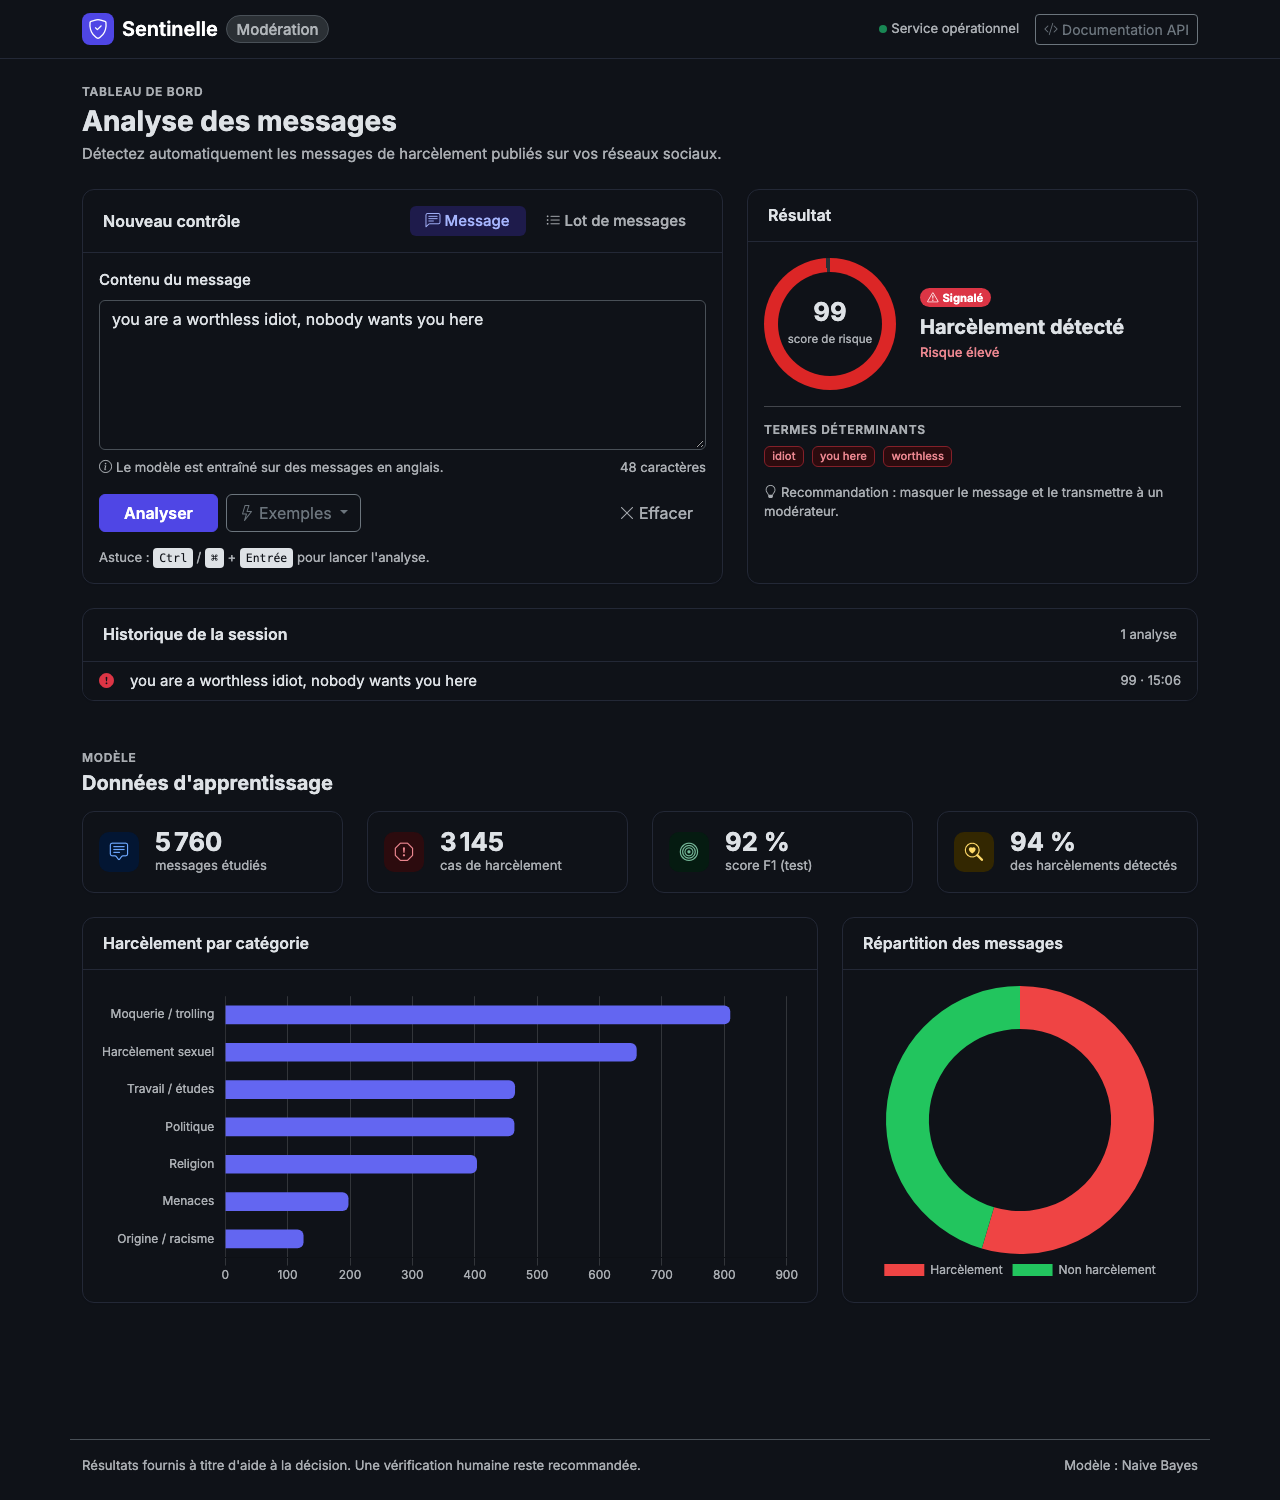

**Un message sain**

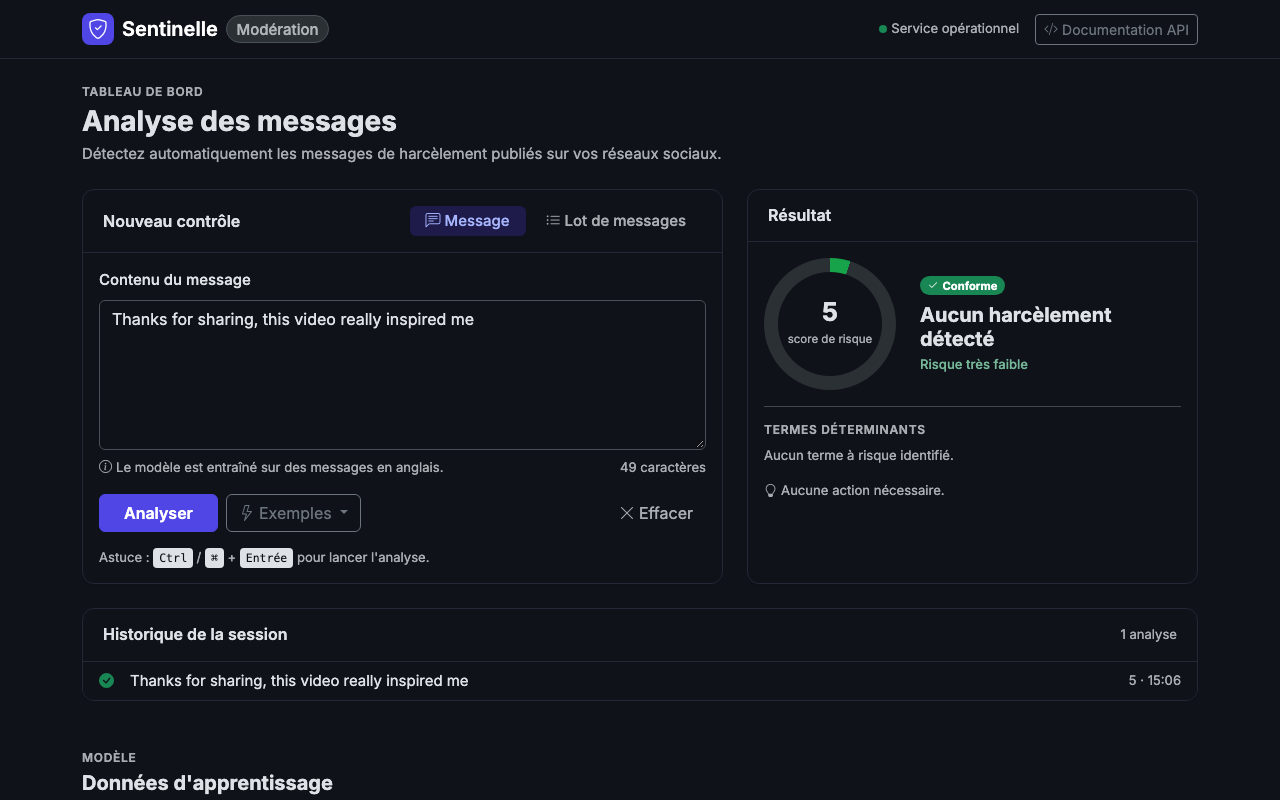

**Plusieurs messages à la fois**

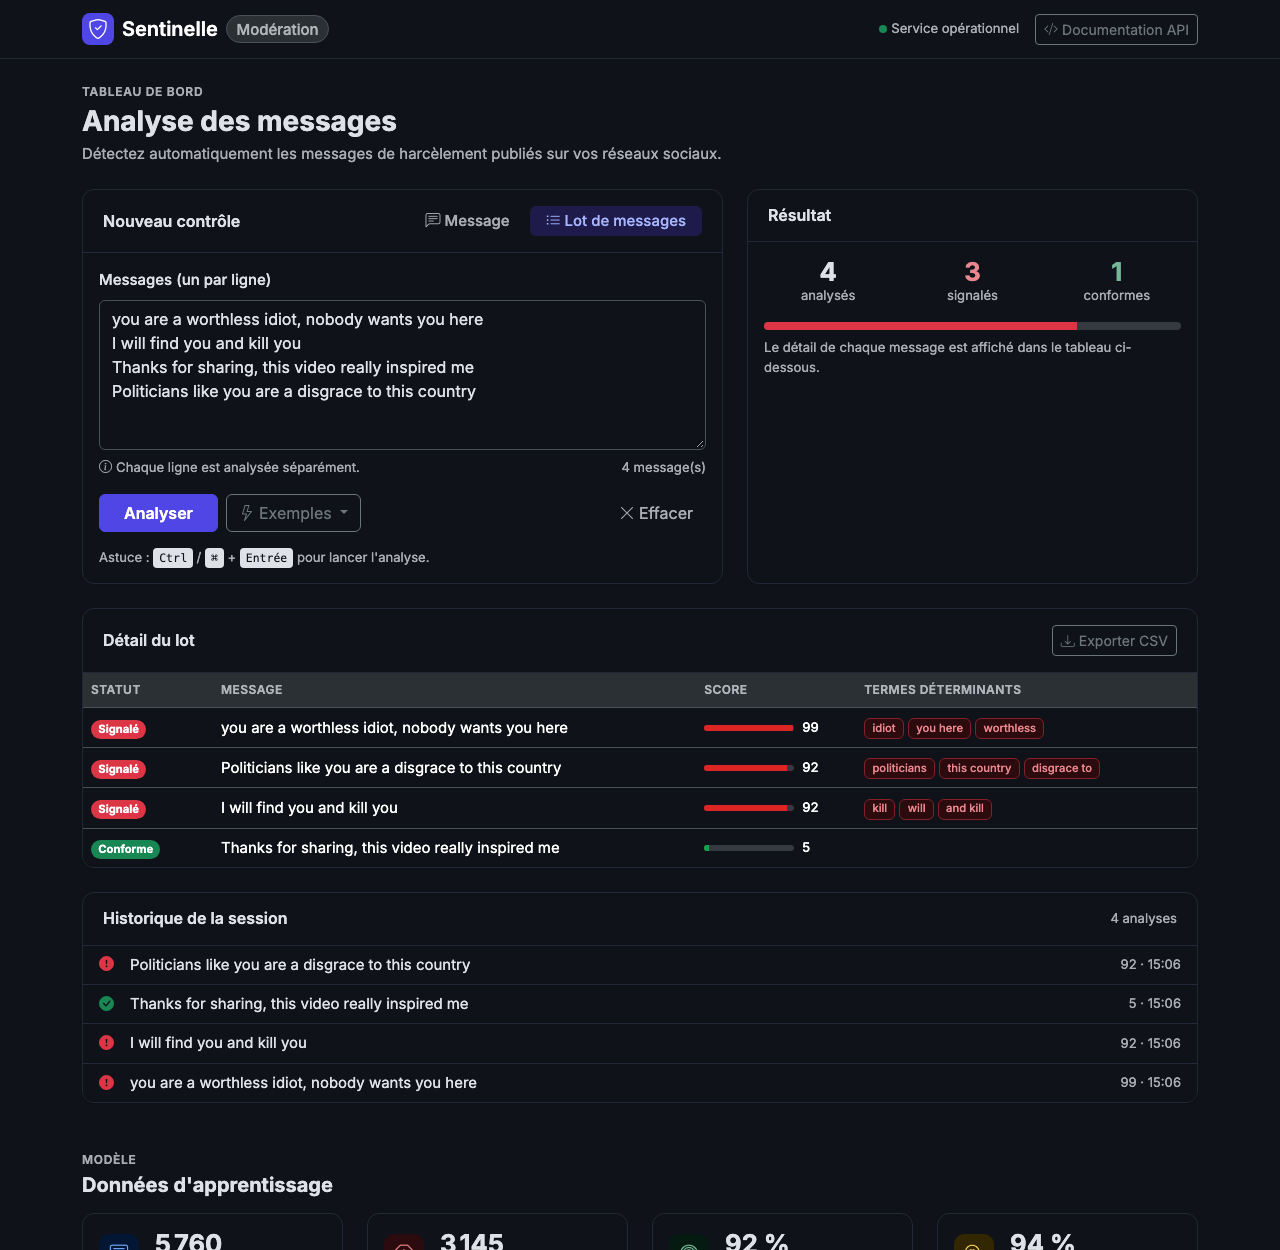

In [40]:
import shutil, urllib.parse
from IPython.display import IFrame, Image

CHROME = next((c for c in ["/Applications/Google Chrome.app/Contents/MacOS/Google Chrome",
                           shutil.which("google-chrome") or "", shutil.which("chromium") or ""]
               if c and Path(c).exists()), None)

def capture(name, query, height=900):
    out = FIG_DIR / name
    if CHROME:
        subprocess.run([CHROME, "--headless=new", "--disable-gpu", "--hide-scrollbars",
                        f"--window-size=1280,{height}", "--virtual-time-budget=4000",
                        f"--screenshot={out}", f"{API}/?{urllib.parse.urlencode(query)}"],
                       capture_output=True, timeout=60)
    return out

shots = {
    "Un message de harcèlement": capture("ui_1_harcelement.png", {"q": samples[0]}, 1500),
    "Un message sain": capture("ui_2_message_sain.png", {"q": samples[2]}, 800),
    "Plusieurs messages à la fois": capture("ui_3_plusieurs_messages.png", {"mode": "many", "q": "\n".join(samples)}, 1250),
}
for title, path in shots.items():
    display(Markdown(f"**{title}**"))
    display(Image(filename=str(path), width=700) if path.exists() else Markdown("_Capture indisponible (Chrome non trouvé)._"))

**Page en direct** (interactive tant que le conteneur tourne) :

In [41]:
IFrame(API + "/", width="100%", height=750)

- **Interface utilisateur** (pour le client) : http://localhost:8000/ (aperçu ci-dessous)
- Documentation technique Swagger (pour les développeurs) : http://localhost:8000/docs

Pour le déploiement en production, voir le `README.md` (build, push dans un registre, `docker run` avec `MONGO_URI`).

<a id="8"></a>
## 8. Conclusion

| | Régression logistique | Naive Bayes ✅ |
|---|---|---|
| F1 / ROC-AUC (test) | ≈ 0,916 / 0,968 | ≈ 0,920 / 0,973 |
| Rappel (harcèlement détecté) | ≈ 0,93 | **≈ 0,94** |
| Précision | **≈ 0,91** | ≈ 0,90 |
| Vitesse | plus lente | **≈ 5-7× plus rapide** |
| Interprétabilité | **coefficients par mot** | probabilités par mot |

- Le nettoyage était indispensable : 19 orthographes du label, 24 types, ≈ 30 % de doublons et des labels contradictoires.
- Le harcèlement se reconnaît par son **vocabulaire thématique** plus que par la forme du message.
- Les deux modèles sont statistiquement équivalents. Naive Bayes est retenu pour son rappel et sa rapidité, et il est servi par une API FastAPI conteneurisée avec MongoDB.

**Limites et pistes** :
- Une partie des messages semble générée ou stéréotypée (« This post is… humor/comedy ») : les scores seront plus bas sur des données réelles.
- Un modèle **Transformer (DistilBERT)** capterait mieux l'ironie (catégorie Troll).
- Pistes supplémentaires : classification multi-classes du type de harcèlement, ajustement du seuil selon le coût des faux négatifs, et suivi de la dérive (drift) via la collection `predictions`.